# Check convergence 

In [1]:
import cobra
import pandas as pd
import numpy as np
import scipy
import warnings
import seaborn as sns
from collections import OrderedDict
from os import listdir
import matplotlib.pyplot as plt

from reframed.community.model import Community
from reframed import Environment, set_default_solver
from steadiercom.cli import load_communities,load_media_db

import sys
sys.path.append("../functions/")
from convergence import SteadierSampleConvergence
from convergence import std_sample_size,std_sampling_grouped,std_sampling_grouped_freq


In [2]:
%load_ext autoreload
%autoreload 2

### Gut microbiome community

Concentration $X_0$ (right after serial transfer) and $X_1$ (right before next transfer) in $t_0$ and $t_1$

$$
X_1 = X_0 *e^{\mu t_1} , X_0 = X_0
$$

Assuming that the cells grow back to the original concentration (after being diluted 1:20 => the cells increase in density by 20 times)

$$
X_1/X_0 = 21 = e^{\mu t} 
$$

The above equation turns into:
$$
ln(X_1/X_0) = \mu t
$$

Which means the avearage growth rate becomes
$$
\mu_{avg} = \frac{ln(20)}{t}
$$

**Methods (From Venturelli et al. 2018): 1:20 dilution every 24 h**

In [3]:
np.log(20)/24

np.float64(0.12482217806474961)

In [4]:
mediadb = "../data/Venturelli2018/generated/media_db.tsv"#path to mediadb
medium = "LB_extend"
growth = np.log(20)/24# average growth rate

models = ["../models/Venturelli2018/species_used_noO2/"+name for name in listdir("../models/Venturelli2018/species_used_noO2/")]
communities = "../data/Venturelli2018/generated/communities_steadiercom/NONE_abundance.tsv"

comm_id = "NONE"

output_dir = "../output/Venturelli2018/convergence_test/"

In [6]:
dfs = []
for d in listdir("../output/Venturelli2018/convergence_test/"):
    if d.endswith(".tsv"):
        df = pd.read_csv("../output/Venturelli2018/convergence_test/"+str(d),sep="\t",index_col=(0,1))
        dfs.append(df)

dfs_tot = pd.concat(dfs,axis=1)
dfs_tot = dfs_tot.T.drop_duplicates().T
dfs_tot.columns = np.arange(0,dfs_tot.shape[1])

# Separate positive and degative values
pos = dfs_tot[dfs_tot>0].dropna(how="all").copy()
neg = dfs_tot[dfs_tot<0].dropna(how="all").map(abs).copy()

neg["type"]="neg"
pos["type"]="pos"
neg.set_index("type",append=True,inplace=True)
pos.set_index("type",append=True,inplace=True)

dfs_tot_abs_nan = pd.concat([pos,neg],axis=0)
dfs_tot_abs = dfs_tot_abs_nan.fillna(0)

In [7]:
dfs_tot_abs.mean().mean()

np.float64(0.006856919207573975)

### Plotting standard deviation based on sample size

The x-axis shows the number of samples in each set. The y-axis shows the standard deviation across all sets of the same size. We expect a higher number of samples in each set to cover more alternative optima and thereby reduce the variance between sets.

We see that there is lower variance between sets when their sample size is large.

In [8]:
base = 10
sample_sizes = [int(base * 2**i) for i in range(12)] 
sample_sizes = [s for s in sample_sizes if s<10000]

sample_sizes_higher_res = np.arange(1000,11000,1000)
sample_sizes_lower_res = np.arange(100,1000,100)


datas,datas_cv = std_sample_size(dfs_tot_abs,sample_sizes)
datas_higher_res,datas_higher_res_cv = std_sample_size(dfs_tot_abs,sample_sizes_higher_res)
datas_lower_res,datas_lower_res_cv = std_sample_size(dfs_tot_abs,sample_sizes_lower_res)

Text(0.5, 0, 'Number of samples')

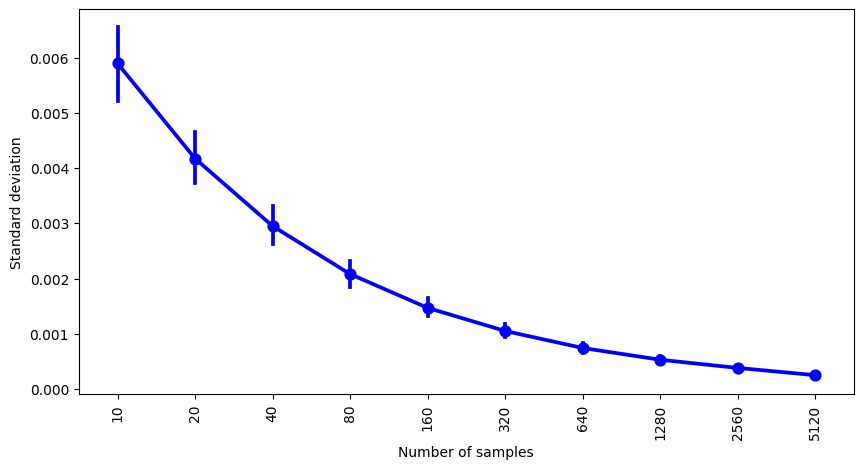

In [9]:
fig = plt.figure(figsize =(10, 5))
ax = fig.add_subplot(111)
ax = sns.pointplot(pd.DataFrame(datas),ax=ax, color="blue")
ticks = plt.xticks(rotation=90)

ax.set_ylabel("Standard deviation")
ax.set_xlabel("Number of samples")
#plt.savefig("figures_meeting/convergence_gut.png",bbox_inches="tight")

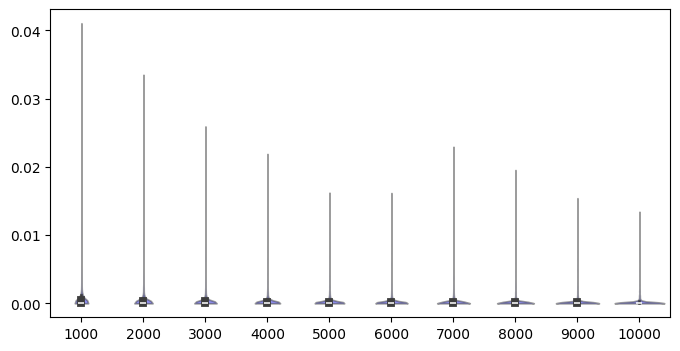

In [10]:
fig = plt.figure(figsize =(8, 4))
ax = fig.add_subplot(111)
ax = sns.violinplot(pd.DataFrame(datas_higher_res),cut=0,ax=ax,color="blue",alpha=0.5)
#ax.set_ylim([0,1e-2])

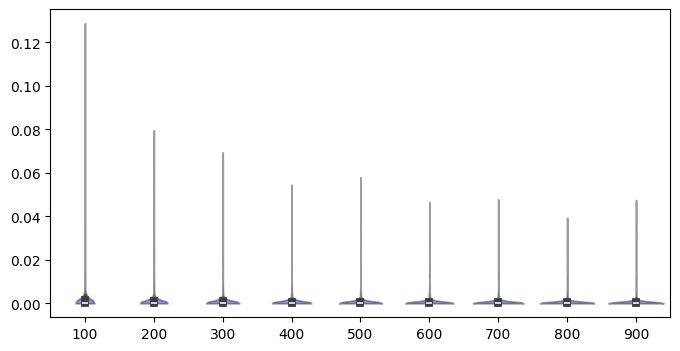

In [11]:
fig = plt.figure(figsize =(8, 4))
ax = fig.add_subplot(111)
ax = sns.violinplot(pd.DataFrame(datas_lower_res),cut=0,ax=ax,color="blue",alpha=0.5)
#ax.set_ylim([0,1e-2])

### Plotting standard deviation based on average flux rate and sample size

The x-axis represent the range of average flux rate across different sets (example: flux is between 1e-6 and 3e-6). The y-axis represents the coefficient of variance. 

We see that when the average flux is higher the coefficient of variance is lower.

In [12]:
statistics,statistics_cv = std_sampling_grouped(dfs_tot_abs,sample_sizes)

statistics_higher_res,statistics_higher_res_cv = std_sampling_grouped(dfs_tot_abs,sample_sizes_higher_res)
       

(0.0, 0.2)

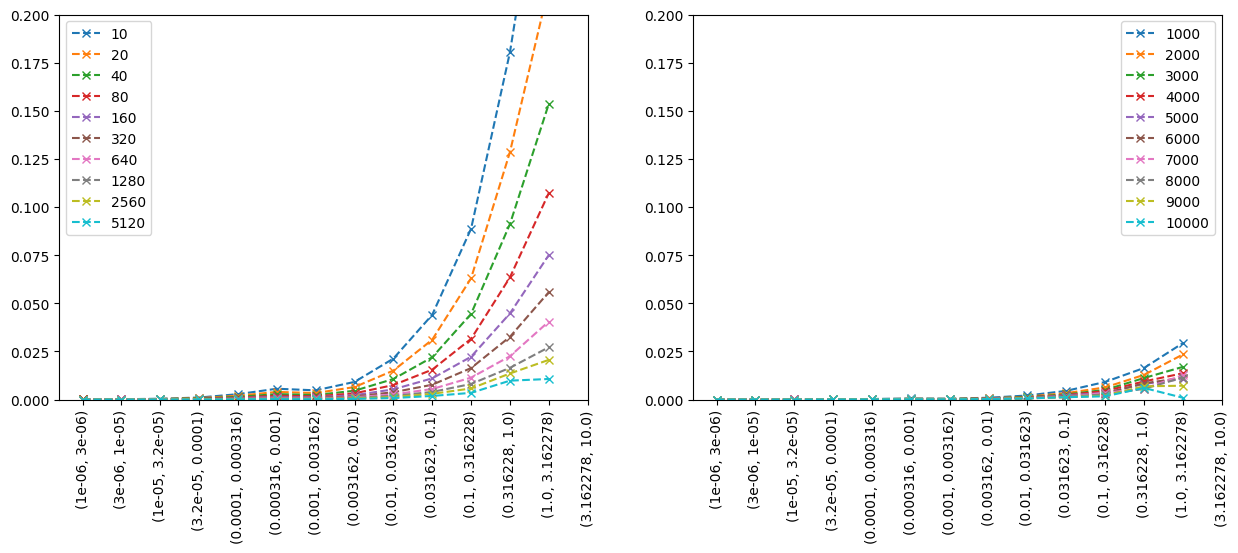

In [13]:
fig,(ax1,ax2) = plt.subplots(1,2,figsize=(15,5))

ax1 = pd.DataFrame(statistics).plot(ax=ax1,marker="x",linestyle="--")
ax1.set_xticks(np.arange(0,len(pd.DataFrame(statistics).index.values)))
ax1.set_xticklabels(pd.DataFrame(statistics).index.values,rotation=90)
ax1.legend(loc="upper left")
ax1.set_ylim([0,0.2])

ax2 = pd.DataFrame(statistics_higher_res).plot(ax=ax2,marker="x",linestyle="--")
ax2.set_xticks(np.arange(0,len(pd.DataFrame(statistics_higher_res).index.values)))
ax2.set_xticklabels(pd.DataFrame(statistics_higher_res).index.values,rotation=90)
ax2.legend(loc="upper right")
ax2.set_ylim([0,0.2])

(0.0, 100.0)

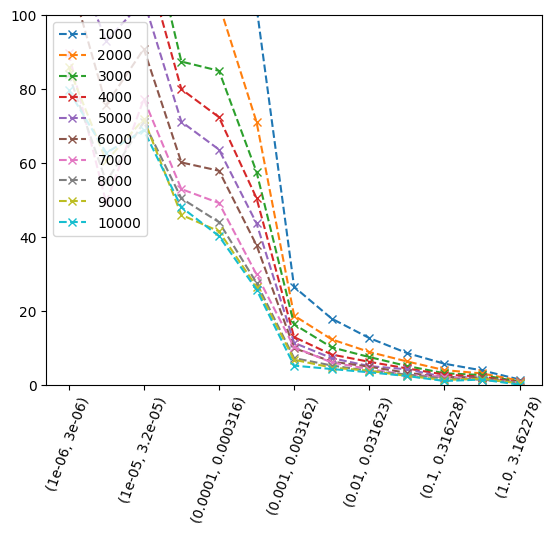

In [14]:
ax = pd.DataFrame(statistics_higher_res_cv).plot(marker="x",linestyle="--")
xticks = plt.xticks(rotation=70)
plt.legend(loc="upper left")
ax.set_ylim([0,100])

In [15]:
stats_high_res = pd.DataFrame(statistics_higher_res_cv)
diff = (stats_high_res.T.iloc[1:].reset_index(drop=True)-stats_high_res.T.iloc[:-1].reset_index(drop=True))

index = pd.Index(list(zip(np.arange(1000,10000,1000),np.arange(2000,11000,1000))))
diff.set_index(keys=index,inplace=True)

In [16]:
diff.T.mean()

1000  2000    -27.563200
2000  3000    -13.468132
3000  4000     -5.943329
4000  5000     -5.247340
5000  6000     -4.920794
6000  7000     -6.704956
7000  8000     -1.599790
8000  9000     -0.110940
9000  10000    -0.795083
dtype: float64

**Sort based on frequency**

In [17]:
statistics_freq,statistics_freq_cv = std_sampling_grouped_freq(dfs_tot_abs,sample_sizes)
statistics_freq_higher_res, statistics_freq_higher_res_cv = std_sampling_grouped_freq(dfs_tot_abs,sample_sizes_higher_res)

(0.0, 0.05)

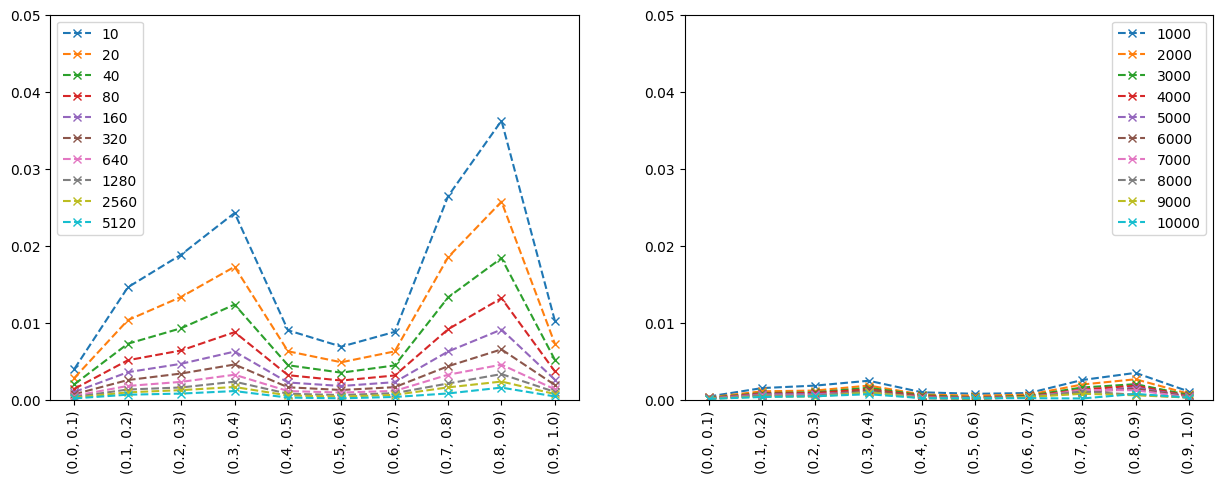

In [18]:
fig,(ax1,ax2) = plt.subplots(1,2,figsize=(15,5))
stats_df_freq = pd.DataFrame(statistics_freq)
ax1 = stats_df_freq.plot(ax=ax1,marker="x",linestyle="--")
labels =ax1.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax1.set_xticklabels(stats_df_freq.index,rotation=90)
ax1.set_ylim([0,0.05])

stats_df_freq = pd.DataFrame(statistics_freq_higher_res)
ax2 = stats_df_freq.plot(ax=ax2,marker="x",linestyle="--")
labels =ax2.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax2.set_xticklabels(stats_df_freq.index,rotation=90)
ax2.set_ylim([0,0.05])


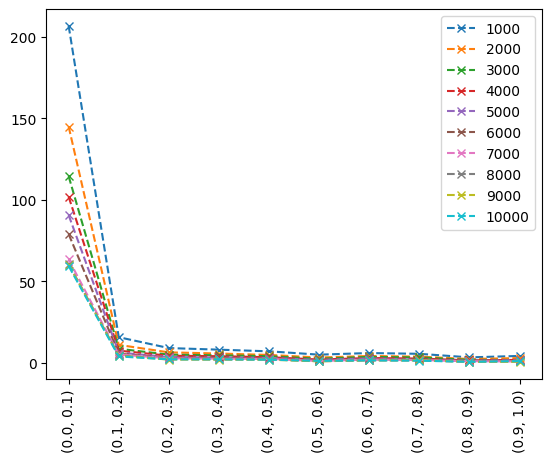

In [19]:
stats_df_freq = pd.DataFrame(statistics_freq_higher_res_cv)
ax = stats_df_freq.plot(marker="x",linestyle="--")
labels =ax.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax.set_xticklabels(stats_df_freq.index,rotation=90)

**Overview over results with filtering**

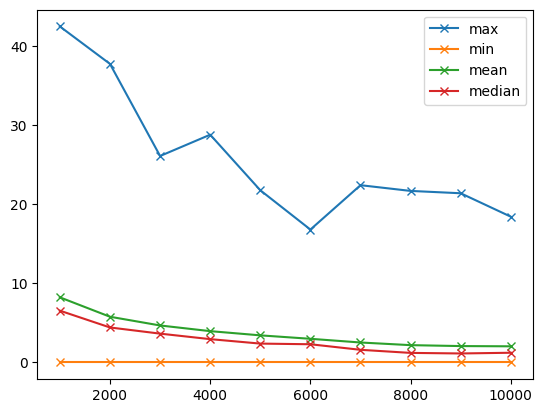

In [20]:
# For sample sizes of x calculate the frequency of the observation of values above 1e-6
sample_size=20000
data_freq = (dfs_tot_abs.T>1e-6).sum()/sample_size
index1 = data_freq>0.1

index2 = dfs_tot_abs.T.mean()>0.001
index = index1*index2
ax = pd.DataFrame(datas_higher_res_cv).loc[index].max().plot(marker='x',label="max")
ax = pd.DataFrame(datas_higher_res_cv).loc[index].min().plot(ax=ax,marker='x',label="min")
ax = pd.DataFrame(datas_higher_res_cv).loc[index].mean().plot(ax=ax,marker='x',label="mean")
ax = pd.DataFrame(datas_higher_res_cv).loc[index].median().plot(ax=ax,marker='x',label="median")
ax.legend()


In [21]:
pd.DataFrame(datas_higher_res_cv).loc[index].mean()

1000     8.232889
2000     5.780650
3000     4.678324
4000     3.960954
5000     3.428399
6000     2.993318
7000     2.525825
8000     2.190938
9000     2.073849
10000    2.043200
dtype: float64

In [22]:
data_high_df = pd.DataFrame(datas_higher_res_cv).loc[index][3000]

max_v = data_high_df.max()
data_high_df[data_high_df>0.5*max_v]

                                                                   type
Bacteroides_ovatus_ATCC_8483           M_hspg_degr_6__91__e__93__  pos     19.807893
Bacteroides_thetaiotaomicron_VPI_5482  M_galur__91__e__93__        pos     16.078886
                                       M_glc_D__91__e__93__        pos     13.557003
                                       M_hspg_degr_3__91__e__93__  neg     15.275914
                                       M_hspg_degr_6__91__e__93__  pos     26.098925
Bacteroides_uniformis_ATCC_8492        M_fum__91__e__93__          neg     13.940244
Bacteroides_vulgatus_ATCC_8482         M_h2o__91__e__93__          neg     19.353123
Collinsella_aerofaciens_ATCC_25986     M_h2__91__e__93__           pos     14.510422
                                       M_hxan__91__e__93__         neg     19.323939
Eggerthella_lenta_DSM_2243             M_3dhcdchol__91__e__93__    pos     18.122221
                                       M_cholate__91__e__93__      neg     19.

In [23]:
index_high = data_high_df[data_high_df>0.5*max_v].index
dfs_tot_abs.loc[index_high].T.mean()

                                                                   type
Bacteroides_ovatus_ATCC_8483           M_hspg_degr_6__91__e__93__  pos     0.001368
Bacteroides_thetaiotaomicron_VPI_5482  M_galur__91__e__93__        pos     0.008515
                                       M_glc_D__91__e__93__        pos     0.008984
                                       M_hspg_degr_3__91__e__93__  neg     0.002584
                                       M_hspg_degr_6__91__e__93__  pos     0.003046
Bacteroides_uniformis_ATCC_8492        M_fum__91__e__93__          neg     0.032895
Bacteroides_vulgatus_ATCC_8482         M_h2o__91__e__93__          neg     0.002884
Collinsella_aerofaciens_ATCC_25986     M_h2__91__e__93__           pos     0.003562
                                       M_hxan__91__e__93__         neg     0.001894
Eggerthella_lenta_DSM_2243             M_3dhcdchol__91__e__93__    pos     0.003831
                                       M_cholate__91__e__93__      neg     0.003779
Euba

## E.coli mutants community

Concentration $X_0$ (right after serial transfer) and $X_1$ (right before next transfer) in $t_0$ and $t_1$

$$
X_1 = X_0 *e^{\mu t_1} , X_0 = X_0
$$

Assuming that the cells grow back to the original concentration (after being diluted 5:995 => has to increase 200 times)

$$
X_1/X_0 = 200 = e^{\mu t} 
$$

The above equation turns into:
$$
ln(X_1/X_0) = \mu t
$$

Which means the avearage growth rate becomes
$$
\mu_{avg} = \frac{ln(200)}{t}
$$

**Methods (From Guillen et al. 2021): 1:200 dilution every 24 h**

In [44]:
np.log(200)/24

np.float64(0.22076322360616818)

**Input data**

In [45]:
mediadb = "../data/Guillen2021/generated/media_db.tsv"#path to mediadb
media = ["M9"]
growth = np.log(200)/24 

models = ["../models/Guillen2021/top_7_strains/"+name for name in listdir("../models/Guillen2021/top_7_strains/")]
communities = "../data/Guillen2021/generated/communities_steadiercom.tsv"

comm_id = "Ecoli_mutants"

output_dir = "../output/Guillen2021/convergence_test/"

**Run SteadierSample**

**Load SteadierSample results**

In [47]:
direct = listdir("../output/Guillen2021/convergence_test/")

dfs = []
for d in direct:
    if d.endswith(".tsv"):
        df = pd.read_csv("../output/Guillen2021/convergence_test/"+str(d),sep="\t",index_col=(0,1))
        dfs.append(df)

dfs_tot = pd.concat(dfs,axis=1)

dfs_tot = dfs_tot.T.drop_duplicates().T

dfs_tot.columns = np.arange(0,dfs_tot.shape[1])
#dfs_tot = dfs_tot.fillna(0)


# Separate positive and degative values
pos = dfs_tot[dfs_tot>0].dropna(how="all").copy()
neg = dfs_tot[dfs_tot<0].dropna(how="all").map(abs).copy()

neg["type"]="neg"
pos["type"]="pos"
neg.set_index("type",append=True,inplace=True)
pos.set_index("type",append=True,inplace=True)

dfs_tot_abs_nan = pd.concat([pos,neg],axis=0)
dfs_tot_abs = dfs_tot_abs_nan.fillna(0)

### Plotting standard deviation based on sample size

The x-axis shows the number of samples in each set. The y-axis shows the standard deviation across all sets of the same size. We expect a higher number of samples in each set to cover more alternative optima and thereby reduce the variance between sets.

We see that there is lower variance between sets when their sample size is large.

In [48]:
base = 10
sample_sizes = [int(base * 2**i) for i in range(12)] 
sample_sizes = [s for s in sample_sizes if s<10000]

sample_sizes_higher_res = np.arange(1000,11000,1000)
sample_sizes_lower_res = np.arange(100,1000,100)


datas,datas_cv = std_sample_size(dfs_tot_abs,sample_sizes)
datas_higher_res,datas_higher_res_cv = std_sample_size(dfs_tot_abs,sample_sizes_higher_res)
datas_lower_res,datas_lower_res_cv = std_sample_size(dfs_tot_abs,sample_sizes_lower_res)

Text(0.5, 0, 'Number of samples')

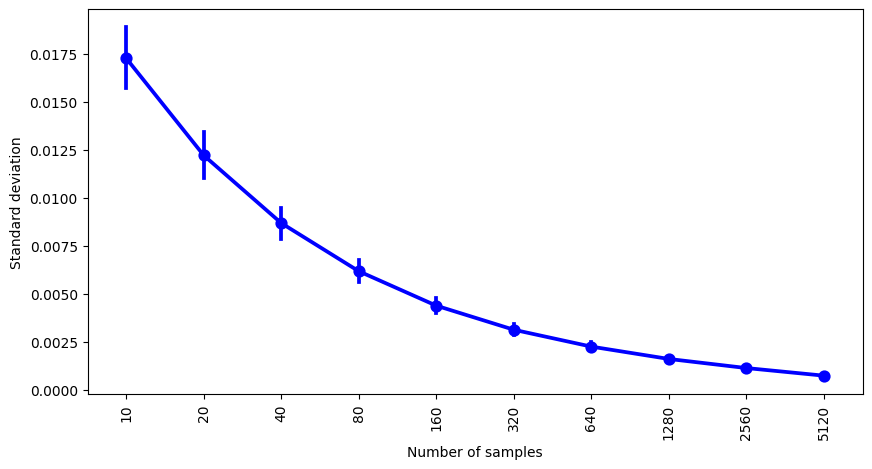

In [49]:
fig = plt.figure(figsize =(10, 5))
ax = fig.add_subplot(111)
ax = sns.pointplot(pd.DataFrame(datas),ax=ax, color="blue")
ticks = plt.xticks(rotation=90)

ax.set_ylabel("Standard deviation")
ax.set_xlabel("Number of samples")
#plt.savefig("figures_meeting/convergence_ecoli.png",bbox_inches="tight")

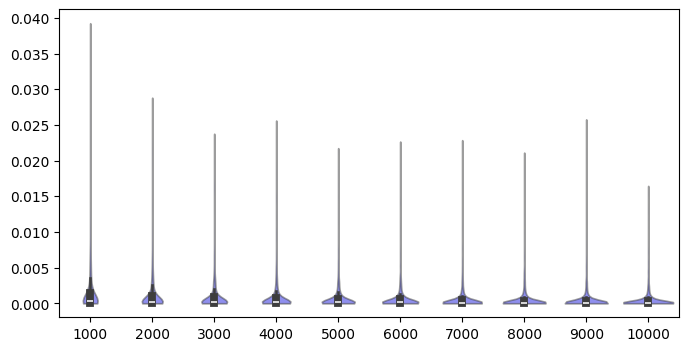

In [50]:
fig = plt.figure(figsize =(8, 4))
ax = fig.add_subplot(111)
ax = sns.violinplot(pd.DataFrame(datas_higher_res),cut=0,ax=ax,color="blue",alpha=0.5)
#ax.set_ylim([0,1e-2])

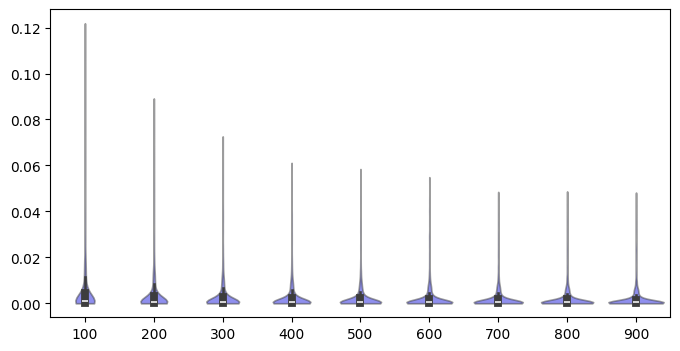

In [51]:
fig = plt.figure(figsize =(8, 4))
ax = fig.add_subplot(111)
ax = sns.violinplot(pd.DataFrame(datas_lower_res),cut=0,ax=ax,color="blue",alpha=0.5)
#ax.set_ylim([0,1e-2])

### Plotting standard deviation based on average flux rate and sample size

The x-axis represent the range of average flux rate across different sets (example: flux is between 1e-6 and 3e-6). The y-axis represents the coefficient of variance. 

We see that when the average flux is higher the coefficient of variance is lower.

In [52]:
statistics,statistics_cv = std_sampling_grouped(dfs_tot_abs,sample_sizes)

statistics_higher_res,statistics_higher_res_cv = std_sampling_grouped(dfs_tot_abs,sample_sizes_higher_res)
       

(0.0, 0.2)

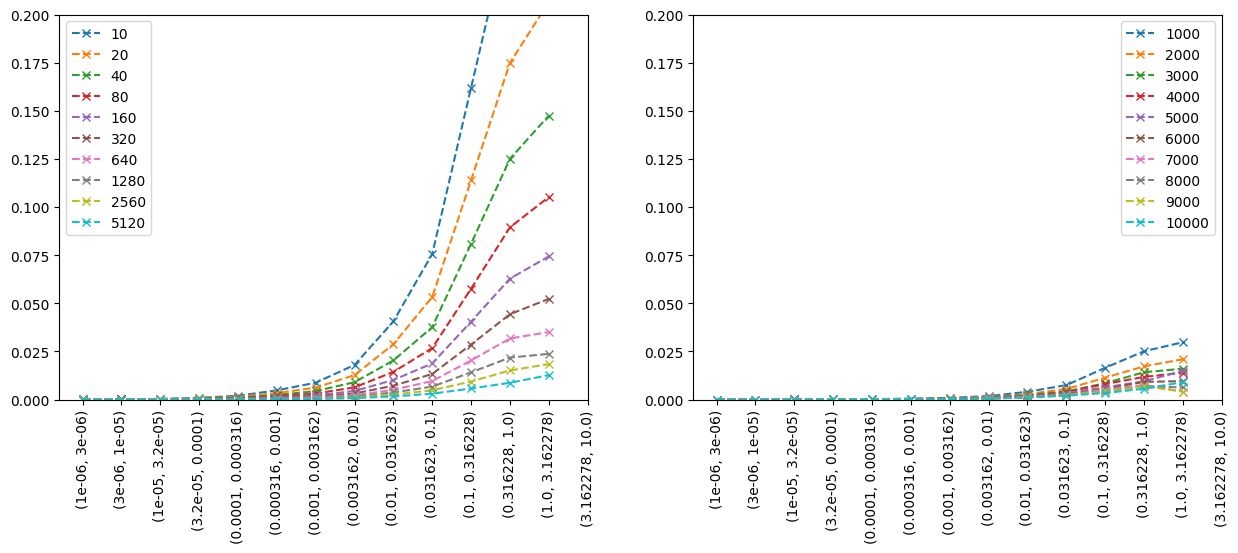

In [53]:
fig,(ax1,ax2) = plt.subplots(1,2,figsize=(15,5))

ax1 = pd.DataFrame(statistics).plot(ax=ax1,marker="x",linestyle="--")
ax1.set_xticks(np.arange(0,len(pd.DataFrame(statistics).index.values)))
ax1.set_xticklabels(pd.DataFrame(statistics).index.values,rotation=90)
ax1.legend(loc="upper left")
ax1.set_ylim([0,0.2])

ax2 = pd.DataFrame(statistics_higher_res).plot(ax=ax2,marker="x",linestyle="--")
ax2.set_xticks(np.arange(0,len(pd.DataFrame(statistics_higher_res).index.values)))
ax2.set_xticklabels(pd.DataFrame(statistics_higher_res).index.values,rotation=90)
ax2.legend(loc="upper right")
ax2.set_ylim([0,0.2])

(0.0, 100.0)

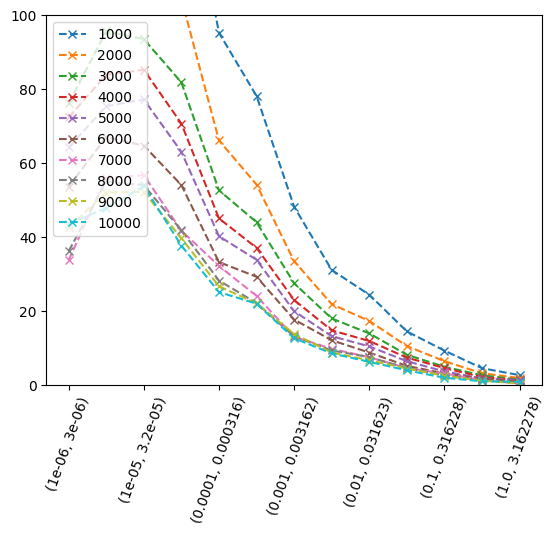

In [54]:
ax = pd.DataFrame(statistics_higher_res_cv).plot(marker="x",linestyle="--")
xticks = plt.xticks(rotation=70)
plt.legend(loc="upper left")
ax.set_ylim([0,100])

In [55]:
stats_high_res = pd.DataFrame(statistics_higher_res_cv)
diff = (stats_high_res.T.iloc[1:].reset_index(drop=True)-stats_high_res.T.iloc[:-1].reset_index(drop=True))

index = pd.Index(list(zip(np.arange(1000,10000,1000),np.arange(2000,11000,1000))))
diff.set_index(keys=index,inplace=True)

In [56]:
diff.T.mean()

1000  2000    -21.999830
2000  3000    -11.575212
3000  4000     -4.703734
4000  5000     -3.736172
5000  6000     -4.569142
6000  7000     -5.171477
7000  8000     -0.601633
8000  9000     -0.255227
9000  10000    -0.605705
dtype: float64

**Sort based on frequency**

In [57]:
statistics_freq,statistics_freq_cv = std_sampling_grouped_freq(dfs_tot_abs,sample_sizes)
statistics_freq_higher_res, statistics_freq_higher_res_cv = std_sampling_grouped_freq(dfs_tot_abs,sample_sizes_higher_res)

(0.0, 0.05)

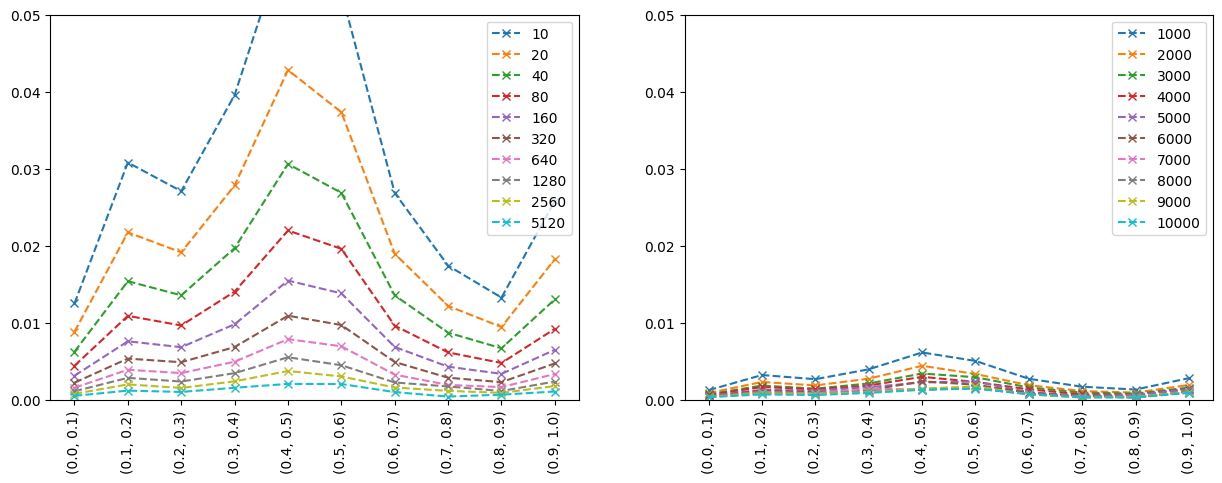

In [58]:
fig,(ax1,ax2) = plt.subplots(1,2,figsize=(15,5))
stats_df_freq = pd.DataFrame(statistics_freq)
ax1 = stats_df_freq.plot(ax=ax1,marker="x",linestyle="--")
labels =ax1.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax1.set_xticklabels(stats_df_freq.index,rotation=90)
ax1.set_ylim([0,0.05])

stats_df_freq = pd.DataFrame(statistics_freq_higher_res)
ax2 = stats_df_freq.plot(ax=ax2,marker="x",linestyle="--")
labels =ax2.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax2.set_xticklabels(stats_df_freq.index,rotation=90)
ax2.set_ylim([0,0.05])


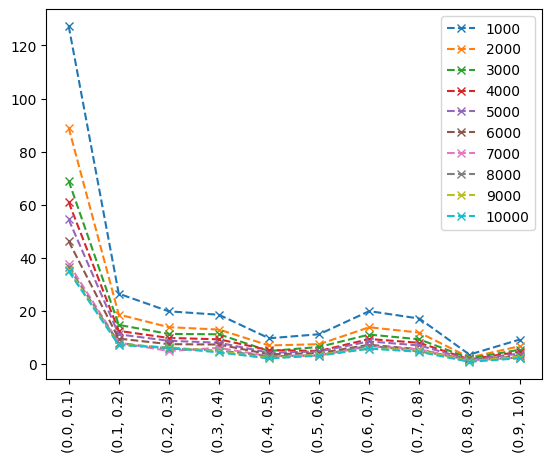

In [59]:
stats_df_freq = pd.DataFrame(statistics_freq_higher_res_cv)
ax = stats_df_freq.plot(marker="x",linestyle="--")
labels =ax.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax.set_xticklabels(stats_df_freq.index,rotation=90)

**Overview over results with filtering**

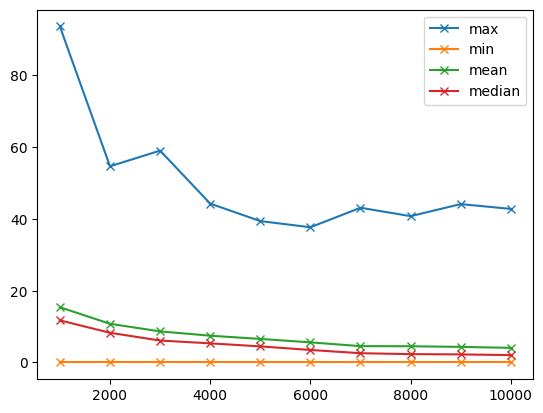

In [60]:
# For sample sizes of x calculate the frequency of the observation of values above 1e-6
sample_size=20000
data_freq = (dfs_tot_abs.T>1e-6).sum()/sample_size
index1 = data_freq>0.1

index2 = dfs_tot_abs.T.mean()>0.001
index = index1*index2

data_high_all_df = pd.DataFrame(datas_higher_res_cv)
ax = data_high_all_df.loc[index].max().plot(marker='x',label="max")
ax = data_high_all_df.loc[index].min().plot(ax=ax,marker='x',label="min")
ax = data_high_all_df.loc[index].mean().plot(ax=ax,marker='x',label="mean")
ax = data_high_all_df.loc[index].median().plot(ax=ax,marker='x',label="median")
ax.legend()


In [61]:
pd.DataFrame(datas_higher_res_cv).loc[index].mean()

1000     15.404483
2000     10.778604
3000      8.664174
4000      7.462259
5000      6.564098
6000      5.610095
7000      4.556290
8000      4.520785
9000      4.349565
10000     4.073935
dtype: float64

In [62]:
data_high_df = pd.DataFrame(datas_higher_res_cv).loc[index][3000]

max_v = data_high_df.max()
data_high_df[data_high_df>0.5*max_v]

                                   type
mutant_bioF  M_LalaDgluMdapDala_e  neg     30.423826
             M_ala__D_e            pos     42.033494
             M_gua_e               neg     37.364495
             M_tyrp_e              neg     32.978201
mutant_bioH  M_3gmp_e              neg     38.068033
             M_ala__D_e            pos     37.175257
             M_cu_e                neg     31.849169
             M_no_e                neg     39.398744
             M_tyrp_e              neg     30.148100
mutant_cysW  M_LalaDgluMdapDala_e  neg     32.705857
mutant_icd   M_ala__D_e            pos     35.649601
             M_cmp_e               neg     30.706182
             M_cu_e                neg     33.112627
             M_dtmp_e              neg     45.888529
             M_indole_e            neg     33.044852
             M_no_e                neg     29.805616
             M_tyrp_e              neg     30.846290
mutant_panZ  M_3cmp_e              neg     34.256502
      

In [63]:
index_high = data_high_df[data_high_df>0.5*max_v].index
dfs_tot_abs.loc[index_high].T.mean()

                                   type
mutant_bioF  M_LalaDgluMdapDala_e  neg     0.002066
             M_ala__D_e            pos     0.001545
             M_gua_e               neg     0.001372
             M_tyrp_e              neg     0.001037
mutant_bioH  M_3gmp_e              neg     0.001957
             M_ala__D_e            pos     0.002278
             M_cu_e                neg     0.008966
             M_no_e                neg     0.001042
             M_tyrp_e              neg     0.002074
mutant_cysW  M_LalaDgluMdapDala_e  neg     0.001192
mutant_icd   M_ala__D_e            pos     0.002630
             M_cmp_e               neg     0.003250
             M_cu_e                neg     0.010690
             M_dtmp_e              neg     0.002124
             M_indole_e            neg     0.010403
             M_no_e                neg     0.001212
             M_tyrp_e              neg     0.002956
mutant_panZ  M_3cmp_e              neg     0.003013
             M_cu_e     